# 07 · The experimental dataset
**Paper:** Sec. III D, Fig. 2, Table VIII (fidelities)  
30 states (5 per SLOCC class) prepared on a Bruker Avance-III 600 MHz spectrometer (¹⁹F three-qubit system) and reconstructed by full state tomography (`mathematica/tomography/`). Four lower-fidelity repeats kept in the CSV with `used_in_paper = False`.  
**Code:** `ann_entanglement.dataset`

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import dataset, checks
all_exp = dataset.load_experimental(paper_only=False)
all_exp[['state_id', 'class', 'fidelity', 'used_in_paper']]

,state_id,class,fidelity,used_in_paper
0,random_sep_2,SEP,0.976,True
1,random_sep_3,SEP,0.959,True
2,random_sep_4,SEP,0.933,True
3,random_sep_5,SEP,0.948,True
4,sep_output,SEP,0.985,True
5,BS1_output,BS1,0.945,True
6,random_bs1_2_output,BS1,0.971,True
7,random_bs1_4_output,BS1,0.981,True
8,random_bs1_5_output,BS1,0.938,True
9,random_bs2_1_output,BS1,0.973,True


In [3]:
exp = dataset.load_experimental()
exp.groupby('class', sort=False)['fidelity'].agg(['count', 'mean', 'min', 'max'])

,count,mean,min,max
class,,,,
SEP,5,0.960,0.933,0.985
BS1,5,0.961,0.938,0.981
BS2,5,0.954,0.926,0.972
BS3,5,0.967,0.954,0.981
W,5,0.940,0.898,0.967
GHZ,5,0.932,0.874,0.955


In [4]:
rep = [checks.check_rho(dataset.row_to_rho(r)) for _, r in exp.iterrows()]
pd.DataFrame({'state': exp.state_id, 'trace': [np.real(r.trace) for r in rep], 'purity': [np.real(r.purity) for r in rep], 'min_eig': [np.real(r.eigenvalues).min() for r in rep]}).describe()

,trace,purity,min_eig
count,3.000e+01,30.000,3.000e+01
mean,1.000e+00,0.788,-1.249e-04
std,9.279e-05,0.111,2.773e-05
min,9.998e-01,0.480,-1.733e-04
25%,1.000e+00,0.739,-1.455e-04
50%,1.000e+00,0.800,-1.277e-04
75%,1.000e+00,0.858,-9.935e-05
max,1.000e+00,0.954,-6.561e-05


Fig. 2 analogue: real parts of one experimental state per class.

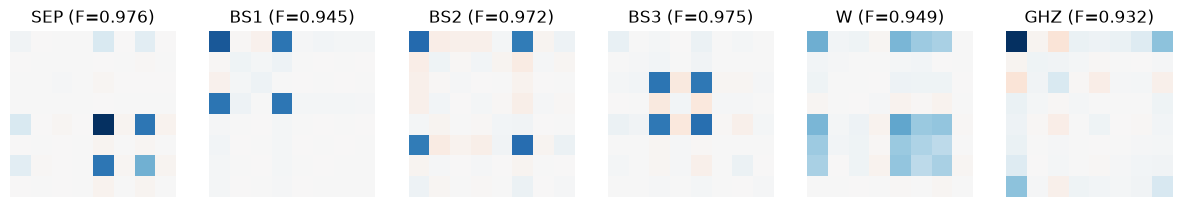

In [5]:
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
for a, (cls, g) in zip(ax, exp.groupby('class', sort=False)):
    a.imshow(dataset.row_to_rho(g.iloc[0]).real, cmap='RdBu', vmin=-0.6, vmax=0.6); a.set_title(f'{cls} (F={g.iloc[0].fidelity:.3f})'); a.axis('off')
plt.show()